In [2]:
import re
import urllib.request

ACCESSION = "L09137.2"


def fetch_ncbi(accession):
    url = ("https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
           f"?db=nuccore&id={accession}&rettype=fasta&retmode=text")
    with urllib.request.urlopen(url, timeout=30) as r:
        return r.read().decode()


def clean(fasta_text):
    lines = [l.strip() for l in fasta_text.splitlines() if l.strip() and not l.startswith(">")]
    return "".join(lines).upper()


try:
    seq = clean(fetch_ncbi(ACCESSION))
except Exception as e:
    print("Could not download from NCBI:", e)
    print("Paste the FASTA sequence into FASTA_MANUAL.")
    FASTA_MANUAL = """
    """
    seq = clean(FASTA_MANUAL)

assert 1000 <= len(seq) <= 3000, f"Sequence has {len(seq)} nucleotides, expected 1000-3000"
assert set(seq) <= set("ACGT"), "Sequence contains letters other than A, C, G, T"
print(f"Sequence: {len(seq)} nucleotides\n")

ENZYMES = [
    {"name": "EcoRI",   "rec_seq": "GAATTC", "cleavage_site": "G^AATTC"},
    {"name": "BamHI",   "rec_seq": "GGATCC", "cleavage_site": "G^GATCC"},
    {"name": "HindIII", "rec_seq": "AAGCTT", "cleavage_site": "A^AGCTT"},
]

COMP = str.maketrans("ACGT", "TGCA")


def complement(s):
    return s.translate(COMP)


def find_sites(seq, rec_seq):
    return [m.start() for m in re.finditer(f"(?={rec_seq})", seq)]


def digest(seq, enzyme):
    rec = enzyme["rec_seq"]
    cut = enzyme["cleavage_site"].index("^")
    sites = find_sites(seq, rec)
    top_cuts = [s + cut for s in sites]
    bottom_cuts = [s + len(rec) - cut for s in sites]
    top_b = [0] + top_cuts + [len(seq)]
    bot_b = [0] + bottom_cuts + [len(seq)]
    fragments = []
    for i in range(len(top_b) - 1):
        top = seq[top_b[i]:top_b[i + 1]]
        bottom = complement(seq[bot_b[i]:bot_b[i + 1]])
        fragments.append({"top": top, "bottom": bottom,
                          "start": top_b[i], "end": top_b[i + 1], "length": len(top)})
    return sites, top_cuts, fragments


def short(s, n=12):
    return s if len(s) <= 2 * n + 3 else s[:n] + "..." + s[-n:]


for enz in ENZYMES:
    sites, cuts, frags = digest(seq, enz)
    rec = enz["rec_seq"]
    c = enz["cleavage_site"].index("^")
    print("=" * 60)
    print(f"{enz['name']}  5'-{rec[:c]}^{rec[c:]}-3'  "
          f"3'-{complement(rec)[:len(rec) - c]}^{complement(rec)[len(rec) - c:]}-5'")
    print(f"Number of sites: {len(sites)}")
    if not sites:
        print("  This enzyme does not cut the sequence.\n")
        continue
    print("Site positions (1-based):", [s + 1 for s in sites])
    print("Cut positions (after nucleotide, top strand):", cuts)
    print("Fragments:")
    for k, f in enumerate(frags, 1):
        print(f"  {k}. {f['start'] + 1}-{f['end']}  ({f['length']} nt)")
        print(f"     5'-{short(f['top'])}-3'")
        print(f"     3'-{short(f['bottom'])}-5'")
    print()

Sequence: 2686 nucleotides

EcoRI  5'-G^AATTC-3'  3'-CTTAA^G-5'
Number of sites: 1
Site positions (1-based): [396]
Cut positions (after nucleotide, top strand): [396]
Fragments:
  1. 1-396  (396 nt)
     5'-TCGCGCGTTTCG...CGACGGCCAGTG-3'
     3'-AGCGCGCAAAGC...CCGGTCACTTAA-5'
  2. 397-2686  (2290 nt)
     5'-AATTCGAGCTCG...GGCCCTTTCGTC-3'
     3'-GCTCGAGCCATG...CCGGGAAAGCAG-5'

BamHI  5'-G^GATCC-3'  3'-CCTAG^G-5'
Number of sites: 1
Site positions (1-based): [417]
Cut positions (after nucleotide, top strand): [417]
Fragments:
  1. 1-417  (417 nt)
     5'-TCGCGCGTTTCG...TCGGTACCCGGG-3'
     3'-AGCGCGCAAAGC...ATGGGCCCCTAG-5'
  2. 418-2686  (2269 nt)
     5'-GATCCTCTAGAG...GGCCCTTTCGTC-3'
     3'-GAGATCTCAGCT...CCGGGAAAGCAG-5'

HindIII  5'-A^AGCTT-3'  3'-TTCGA^A-5'
Number of sites: 1
Site positions (1-based): [447]
Cut positions (after nucleotide, top strand): [447]
Fragments:
  1. 1-447  (447 nt)
     5'-TCGCGCGTTTCG...TGCAGGCATGCA-3'
     3'-AGCGCGCAAAGC...CCGTACGTTCGA-5'
  2. 448-2686  

LC946308.1: 1778 nt  |  LC946308.1 Porcine circovirus 2 AQ-183709 DNA, complete genome
LC946307.1: 1778 nt  |  LC946307.1 Porcine circovirus 2 AQ-211537 DNA, complete genome

Enzyme    LC946308.1                      LC946307.1                      Result
EcoRI     [1431, 347]                     [1431, 347]                     same
BamHI     [1778]                          [1778]                          same
HindIII   [1778]                          [1778]                          same
All 3     [1431, 347]                     [1431, 347]                     same


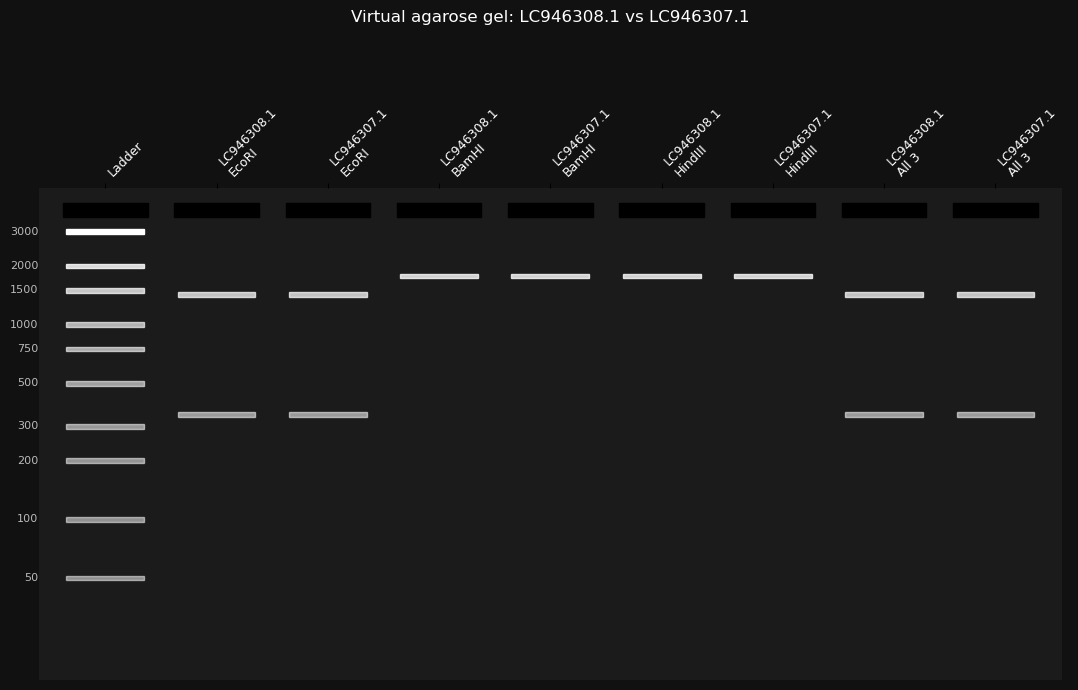

In [3]:
import json
import re
import time
import urllib.parse
import urllib.request

import matplotlib.pyplot as plt
import numpy as np

SEARCH_TERM = "Porcine circovirus 2[Organism] AND complete genome[Title] AND 1700:1800[SLEN]"
ACCESSIONS = None
CIRCULAR = False

ENZYMES = [
    {"name": "EcoRI",   "rec_seq": "GAATTC", "cleavage_site": "G^AATTC"},
    {"name": "BamHI",   "rec_seq": "GGATCC", "cleavage_site": "G^GATCC"},
    {"name": "HindIII", "rec_seq": "AAGCTT", "cleavage_site": "A^AGCTT"},
]

LADDER = [50, 100, 200, 300, 500, 750, 1000, 1500, 2000, 3000]
EUTILS = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/"


def eutils(endpoint, **params):
    url = EUTILS + endpoint + "?" + urllib.parse.urlencode(params)
    with urllib.request.urlopen(url, timeout=60) as r:
        text = r.read().decode()
    time.sleep(0.4)
    return text


def parse_fasta(text):
    records = []
    for block in text.strip().split(">")[1:]:
        lines = block.strip().splitlines()
        header = lines[0]
        seq = "".join(l.strip() for l in lines[1:]).upper()
        records.append((header.split()[0], header, seq))
    return records


def load_genomes():
    if ACCESSIONS:
        ids = ",".join(ACCESSIONS)
    else:
        found = json.loads(eutils("esearch.fcgi", db="nuccore", term=SEARCH_TERM,
                                  retmax=20, retmode="json"))["esearchresult"]["idlist"]
        ids = ",".join(found)
    records = parse_fasta(eutils("efetch.fcgi", db="nuccore", id=ids, rettype="fasta", retmode="text"))
    chosen = []
    for acc, header, seq in records:
        if not (1000 <= len(seq) <= 3000) or not set(seq) <= set("ACGT"):
            continue
        if any(seq == s for _, _, s in chosen):
            continue
        chosen.append((acc, header, seq))
        if len(chosen) == 2:
            break
    if len(chosen) < 2:
        raise RuntimeError("Could not find two different genomes of 1000-3000 nucleotides")
    return {acc: seq for acc, _, seq in chosen}, {acc: header for acc, header, _ in chosen}


def cut_positions(seq, enzyme):
    rec = enzyme["rec_seq"]
    offset = enzyme["cleavage_site"].index("^")
    return [m.start() + offset for m in re.finditer(f"(?={rec})", seq)]


def fragment_sizes(seq, cuts):
    cuts = sorted(set(cuts))
    if CIRCULAR:
        if not cuts:
            return [len(seq)]
        sizes = [b - a for a, b in zip(cuts, cuts[1:])]
        sizes.append(len(seq) - cuts[-1] + cuts[0])
        return sorted(sizes, reverse=True)
    bounds = [0] + cuts + [len(seq)]
    return sorted([b - a for a, b in zip(bounds, bounds[1:])], reverse=True)


def digest_all(seq):
    results = {}
    for enz in ENZYMES:
        results[enz["name"]] = fragment_sizes(seq, cut_positions(seq, enz))
    all_cuts = [c for enz in ENZYMES for c in cut_positions(seq, enz)]
    results["All 3"] = fragment_sizes(seq, all_cuts)
    return results


def draw_gel(lanes, title, filename):
    fig, ax = plt.subplots(figsize=(max(8, 1.0 * len(lanes) + 2), 7))
    fig.patch.set_facecolor("#111111")
    ax.set_facecolor("#1b1b1b")
    for i, (label, sizes) in enumerate(lanes):
        ax.add_patch(plt.Rectangle((i - 0.38, -np.log10(4200)), 0.76, 0.07,
                                   color="#000000", zorder=1))
        for s in sizes:
            y = -np.log10(s)
            strength = 0.5 + 0.5 * min(s, 3000) / 3000
            ax.add_patch(plt.Rectangle((i - 0.35, y - 0.012), 0.7, 0.024,
                                       color="white", alpha=strength, zorder=2))
    for s in LADDER:
        ax.text(-0.6, -np.log10(s), f"{s}", color="#bbbbbb", ha="right", va="center", fontsize=8)
    ax.set_xticks(range(len(lanes)))
    ax.set_xticklabels([l for l, _ in lanes], rotation=45, ha="left", color="white", fontsize=9)
    ax.xaxis.tick_top()
    ax.set_yticks([])
    ax.set_xlim(-0.6, len(lanes) - 0.4)
    ax.set_ylim(-np.log10(15), -np.log10(5000))
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(title, color="white", pad=60)
    plt.tight_layout()
    fig.savefig(filename, dpi=150, facecolor=fig.get_facecolor())
    plt.show()


genomes, headers = load_genomes()
names = list(genomes)
A, B = names

for n in names:
    print(f"{n}: {len(genomes[n])} nt  |  {headers[n]}")
print()

digests = {n: digest_all(genomes[n]) for n in names}

print(f"{'Enzyme':<10}{A:<32}{B:<32}Result")
for key in digests[A]:
    sa, sb = digests[A][key], digests[B][key]
    print(f"{key:<10}{str(sa):<32}{str(sb):<32}{'same' if sa == sb else 'DIFFERENT'}")

lanes = [("Ladder", LADDER)]
for key in digests[A]:
    lanes.append((f"{A}\n{key}", digests[A][key]))
    lanes.append((f"{B}\n{key}", digests[B][key]))

draw_gel(lanes, f"Virtual agarose gel: {A} vs {B}", "gel.png")